# Home

Forecast for now (temperature, pictogram), estimated solar production for today, the next 48 h of temperature and rain/snow, and a daily outlook (min/max, precipitation, sunshine).

Data: MeteoSwiss local forecast (OGD), updated hourly.

In [1]:
import json
import localforecast as lf
import screens

In [2]:
# Find point ids: search by town, station abbreviation or postal code
lf.find_point("Renens")

,point_id,point_type_id,point_name,station_abbr,postal_code,point_type_en,point_height_masl
1134,102000,2,Renens VD,NaN,1020.0,Postal code center,419.0
1135,102200,2,Chavannes-près-Renens,NaN,1022.0,Postal code center,400.0


In [3]:
# ── Configuration ──────────────────────────────────────────────
POINT = (102000, 2)       # (point_id, point_type_id): Renens VD, postal code 1020
PV = {"kwp": 7.905, "tilt": 29, "azimuth": 212, "derate": 0.88}   # azimuth 180 = south
HOURS, DAYS = 39, 5       # chart: 39 h from the last 00:00 / 12:00, daily outlook days
# ───────────────────────────────────────────────────────────────

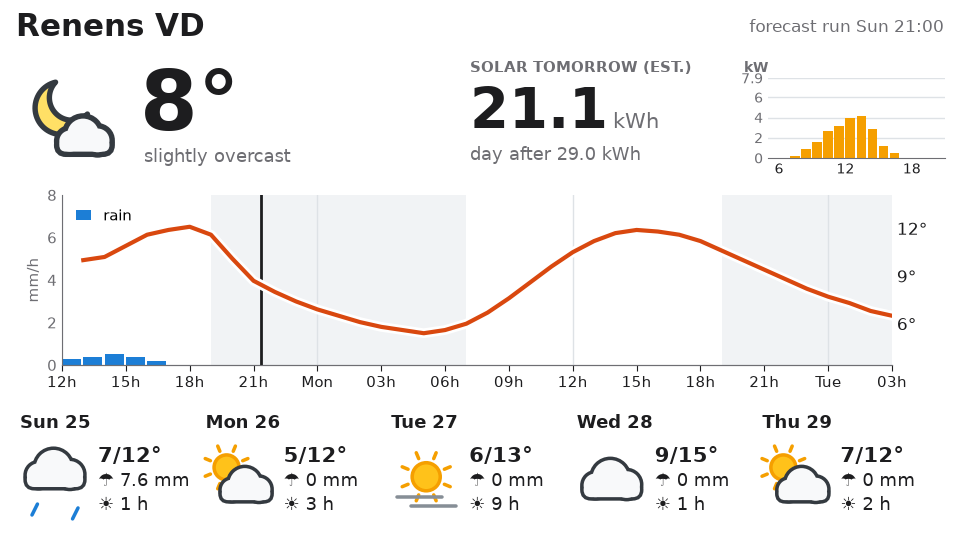

In [4]:
run, data = lf.fetch([POINT], lf.HOME_PARAMS)
hourly, daily = data[POINT]
view = lf.home_view(run, hourly, daily, lf.point_info(POINT), PV, hours=HOURS, days=DAYS)
screens.render(screens.home, view, colour=True)

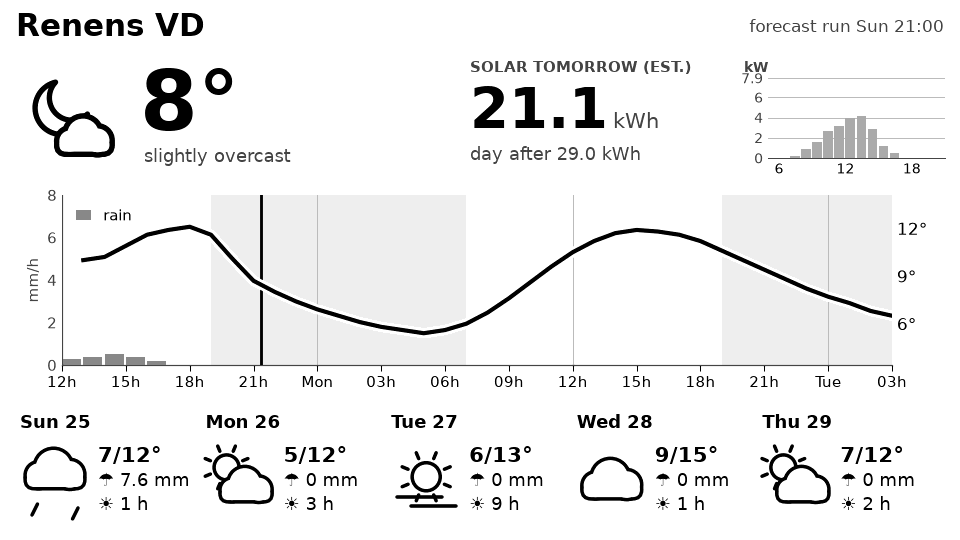

In [5]:
# As on the LilyGO T5 4.7" e-paper: 960×540, 16 grey levels
img = screens.render(screens.home, view)
img

In [6]:
# The payload a display would receive
print(f"{len(json.dumps(view, separators=(',', ':')))} bytes as JSON, "
      f"{len(screens.epd_buffer(img)):,} bytes as a 4-bit frame buffer")
print(json.dumps(view, indent=1)[:1500])

2689 bytes as JSON, 259,200 bytes as a 4-bit frame buffer
{
 "view": "home",
 "name": "Renens VD",
 "run": "2026-10-25T21:00:00+01:00",
 "now": {
  "time": "2026-10-25T22:00:00+01:00",
  "temp": 8.0,
  "icon": 102
 },
 "solar": {
  "kwp": 7.905,
  "date": "2026-10-26",
  "tomorrow": true,
  "kwh": 21.1,
  "peak_kw": 4.16,
  "next_kwh": 29.0,
  "hourly_kw": [
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.15,
   0.84,
   1.62,
   2.66,
   3.18,
   3.93,
   4.16,
   2.83,
   1.19,
   0.54,
   0.03,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0
  ],
  "hours": [
   0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23
  ]
 },
 "hourly": {
  "time": [
   "2026-10-25T13:00:00+01:00",
   "2026-10-25T14:00:00+01:00",
   "2026-10-25T15:00:00+01:00",
   "2026-10-25T16:00:00+01:00",
   "2026-10-25T17:00:00+01:00",
   "2026-10-25T18:00:00+01:00",
   "2026-10-25T19:00:00+01:00",
   "2